# Final revision — Step 6

Run this notebook from this copied project folder, or set `NETWORK_ANALYSIS_LOCAL_ROOT` to its absolute path. Run Steps 01–07 in separate kernels. Existing outputs in this copy may be overwritten; the source repository is untouched.

The approved hypotheses, thresholds, seeds, null ensembles and removal protocol are retained. Cleared outputs avoid presenting historical execution as validation of revised code. Step 04 is the full historical generation workflow and is computationally expensive; the supplied cached ensembles allow Steps 05–07 to run without regenerating it. Consult `VALIDATION.md` for exactly what was rerun.


# Step 6: Structural resilience metrics, H1 and H2

**Scope.** This notebook calculates the approved resilience metrics using the validated Step 5 removal plans and saved networks, then applies the approved H1 and H2 rules. **It does not run Step 7 or any single-airport removal, and it does not include strength targeting.**

| Metric | Definition (N is the original airport count) |
|---|---|
| Directed global efficiency | Sum of 1/d over all ordered pairs, divided by N(N−1); unreachable or removed pairs contribute 0 |
| Ordered-pair reachability | Number of ordered pairs with a directed path, divided by N(N−1) |
| Largest SCC | Size of the largest strongly connected component, divided by N |

**H1** uses the observed networks only. **H2** uses the primary directed null only. The reciprocal-pair null is supplementary and does not affect any H2 verdict.

## Section 6.0: Setup and inputs

In [1]:
import os
import time
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components, shortest_path

# Local execution is enabled only when this environment variable is set.
# It is not set on Colab, so Colab always uses the Google Drive path below.
LOCAL_PROJECT_ROOT = os.environ.get("NETWORK_ANALYSIS_LOCAL_ROOT")

if LOCAL_PROJECT_ROOT:
    BASE = Path(LOCAL_PROJECT_ROOT).expanduser().resolve() / "Data"
elif (Path.cwd() / "Data").is_dir():
    BASE = Path.cwd() / "Data"
else:
    from google.colab import drive
    drive.mount("/content/drive")

    # Notice the trailing space after 'Network Analysis '
    BASE = Path("/content/drive/MyDrive/Network Analysis /Data")

PROCESSED = BASE / "Processed"
NULLS = PROCESSED / "Nulls"
PLANS = PROCESSED / "Removal_Plans"
RESILIENCE = PROCESSED / "Resilience"
PROJECT_ROOT = BASE.parent
TABLES = PROJECT_ROOT / "Results" / "Tables"
FIGURES = PROJECT_ROOT / "Results" / "Figures"
RESILIENCE.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

AIRLINES = ["AA", "DL", "WN"]
NETWORK_SETS = ["observed", "directed", "reciprocal"]
NULL_LABELS = {"directed": "Primary directed null", "reciprocal": "Supplementary reciprocal-pair null"}
LEVELS = [5, 10, 15, 20]
METRICS = ["Efficiency", "Reachability", "Largest SCC"]
STRATEGIES = ["Degree", "Betweenness"]
RANDOM_LABEL = "Random (mean of matched orders)"
EXPECTED_PRIMARY = 200
EXPECTED_SUPPLEMENTARY = 100
RANDOM_TRIALS = 100
TIE_REPLICATES = 100
ZERO_WIDTH = 1e-12
NEAR_ZERO_WIDTH = 0.001

validation = []
timings = {}


class StopProtocolError(RuntimeError):
    pass


def check(name, condition, detail=""):
    if not bool(condition):
        pd.DataFrame(validation).to_csv(TABLES / "06_validation_checks.csv", index=False)
        raise StopProtocolError(f"FAILED: {name}. {detail}")
    validation.append({"Check": name, "Result": "PASS", "Detail": str(detail)})


def removal_count(n, p):
    """p is in percentage points (5, 10, 15 or 20); halves round up."""
    return (2 * n * p + 100) // 200


OBS = {}

for airline in AIRLINES:
    nodes = pd.read_csv(PROCESSED / f"{airline}_nodes.csv")
    edges = pd.read_csv(PROCESSED / f"{airline}_edges.csv")
    ids = np.sort(nodes["airport_id"].to_numpy(dtype=np.int64))
    OBS[airline] = {
        "ids": ids, "n": len(ids), "codes": nodes.set_index("airport_id").loc[ids, "code"].to_numpy(),
        "source": np.searchsorted(ids, edges["source"].to_numpy(dtype=np.int64)),
        "target": np.searchsorted(ids, edges["target"].to_numpy(dtype=np.int64))
    }

LEVEL_K = {a: {p: removal_count(OBS[a]["n"], p) for p in LEVELS} for a in AIRLINES}
orders_table = pd.read_csv(TABLES / "04_random_removal_orders.csv").sort_values(["Airline", "Trial"])
RANDOM_ORDERS = {
    airline: [
        np.searchsorted(OBS[airline]["ids"], np.fromiter(map(int, text.split()), dtype=np.int64))
        for text in orders_table.loc[orders_table["Airline"] == airline, "Airport order (BTS IDs)"]
    ]
    for airline in AIRLINES
}

for airline in AIRLINES:
    check(f"{airline}: 100 approved random orders loaded", len(RANDOM_ORDERS[airline]) == RANDOM_TRIALS, len(RANDOM_ORDERS[airline]))


def load_networks(airline, model):
    obs = OBS[airline]
    if model == "observed":
        return [(0, obs["source"], obs["target"])]
    stored = np.load(NULLS / f"{airline}_{model}_null_networks.npz")
    assert np.array_equal(stored["airport_ids"], obs["ids"])
    networks = [
        (i, np.searchsorted(obs["ids"], stored["source"][i]), np.searchsorted(obs["ids"], stored["target"][i]))
        for i in range(stored["source"].shape[0])
    ]
    if model == "directed":
        extra = np.load(NULLS / f"{airline}_directed_null_networks_expansion_chains_100_199.npz")
        assert np.array_equal(extra["airport_ids"], obs["ids"])
        networks += [
            (int(chain), np.searchsorted(obs["ids"], extra["source"][i]), np.searchsorted(obs["ids"], extra["target"][i]))
            for i, chain in enumerate(extra["chain_ids"].tolist())
        ]
    return networks


def load_rankings(airline, model):
    stored = np.load(PLANS / f"{airline}_{model}_targeted_rankings.npz")
    assert np.array_equal(stored["airport_ids"], OBS[airline]["ids"])
    ids = OBS[airline]["ids"]
    rankings = {}
    for index, network in enumerate(stored["network_ids"].tolist()):
        rankings[int(network)] = {
            "Degree": np.searchsorted(ids, stored["degree_order"][index]),
            "Betweenness": np.searchsorted(ids, stored["betweenness_order"][index])
        }
    return rankings


def directed_matrix(source, target, n):
    return csr_matrix((np.ones(len(source), dtype=float), (source, target)), shape=(n, n))


def connectivity(A, universe_n):
    """Efficiency, reachability and largest SCC on the remaining network, using the original universe."""
    d = shortest_path(A, method="D", unweighted=True, directed=True)
    reachable = np.isfinite(d) & (d > 0)
    denominator = universe_n * (universe_n - 1)
    labels = connected_components(A, directed=True, connection="strong")[1]
    return float((1.0 / d[reachable]).sum() / denominator), float(reachable.sum() / denominator), float(np.bincount(labels).max() / universe_n)


def after_removal(A, removed, n):
    keep = np.ones(n, dtype=bool)
    keep[removed] = False
    return connectivity(A[keep, :][:, keep], n)


def evaluate_network(airline, source, target, ranking):
    obs = OBS[airline]
    n = obs["n"]
    A = directed_matrix(source, target, n)
    intact = connectivity(A, n)
    targeted = {}
    for strategy in STRATEGIES:
        targeted[strategy] = {p: after_removal(A, ranking[strategy][:k], n) for p, k in LEVEL_K[airline].items()}
    random_values = np.zeros((len(RANDOM_ORDERS[airline]), len(LEVELS), 3))
    for t, order in enumerate(RANDOM_ORDERS[airline]):
        for j, p in enumerate(LEVELS):
            random_values[t, j] = after_removal(A, order[:LEVEL_K[airline][p]], n)
    return intact, targeted, random_values


print("Inputs loaded.")

Inputs loaded.


## Section 6.1: Resilience metrics

Each network uses its fixed Step 5 rankings and the same 100 random orders. Paired random-trial outcomes for every network are stored in `Data/Processed/Resilience/`.

In [2]:
started = time.perf_counter()
outcome_rows, intact_rows = [], []
OBSERVED_RANDOM = {}
TRIAL_STORE = {}

for airline in AIRLINES:
    for model in NETWORK_SETS:
        networks = load_networks(airline, model)
        rankings = load_rankings(airline, model)
        n = OBS[airline]["n"]
        store = np.zeros((len(networks), RANDOM_TRIALS, len(LEVELS), 3))

        for index, (network, source, target) in enumerate(networks):
            intact, targeted, random_values = evaluate_network(airline, source, target, rankings[network])
            store[index] = random_values
            intact_rows.append({"Airline": airline, "Network set": model, "Network": network,
                                "Intact efficiency": intact[0], "Intact reachability": intact[1], "Intact largest SCC": intact[2]})

            for strategy in STRATEGIES:
                for p in LEVELS:
                    eff, reach, scc = targeted[strategy][p]
                    outcome_rows.append({"Airline": airline, "Network set": model, "Network": network, "Strategy": strategy, "Level": p,
                                         "Efficiency": eff, "Efficiency retention": eff / intact[0], "Reachability": reach, "Largest SCC": scc})

            means = random_values.mean(axis=0)
            for j, p in enumerate(LEVELS):
                eff, reach, scc = means[j]
                outcome_rows.append({"Airline": airline, "Network set": model, "Network": network, "Strategy": RANDOM_LABEL, "Level": p,
                                     "Efficiency": eff, "Efficiency retention": eff / intact[0], "Reachability": reach, "Largest SCC": scc})

            if model == "observed":
                OBSERVED_RANDOM[airline] = {"intact": intact, "values": random_values}

        TRIAL_STORE[(airline, model)] = store
        np.savez_compressed(
            RESILIENCE / f"{airline}_{model}_paired_random_trials.npz",
            network_ids=np.array([network for network, _, _ in networks]), trials=np.arange(RANDOM_TRIALS),
            levels=np.array(LEVELS), metrics=np.array(METRICS), values=store
        )

outcomes_df = pd.DataFrame(outcome_rows)
intact_df = pd.DataFrame(intact_rows)
outcomes_df.to_csv(TABLES / "06_network_outcomes.csv", index=False)
intact_df.to_csv(TABLES / "06_intact_baselines.csv", index=False)

trial_rows = []
for airline in AIRLINES:
    values = OBSERVED_RANDOM[airline]["values"]
    intact = OBSERVED_RANDOM[airline]["intact"]
    for t in range(RANDOM_TRIALS):
        for j, p in enumerate(LEVELS):
            eff, reach, scc = values[t, j]
            trial_rows.append({"Airline": airline, "Trial": t, "Level": p, "Efficiency": eff, "Efficiency retention": eff / intact[0],
                               "Reachability": reach, "Largest SCC": scc,
                               "Efficiency loss": intact[0] - eff, "Reachability loss": intact[1] - reach, "Largest SCC loss": intact[2] - scc})
pd.DataFrame(trial_rows).to_csv(TABLES / "06_observed_random_trials.csv", index=False)
timings["Metric calculation"] = time.perf_counter() - started

display(intact_df[intact_df["Network set"] == "observed"].drop(columns=["Network set", "Network"]))
print(f"Outcome rows: {len(outcomes_df):,}")

Outcome rows: 10,836


,Airline,Intact efficiency,Intact reachability,Intact largest SCC
0,AA,0.492412,1.0,1.0
301,DL,0.477913,1.0,1.0
602,WN,0.572178,1.0,1.0


## Section 6.2: H1, targeted versus random removal (observed networks)

Loss is the intact value minus the value after removal, so a positive loss means connectivity was lost. A cell is met when the targeted loss exceeds the 97.5th percentile of the 100 random-removal losses.

- **Supported:** efficiency met at all 4 levels, and reachability and largest SCC each met at 3 or more levels.
- **Partly supported:** efficiency met at 2 or 3 levels, or at 4 levels without the other two conditions.
- **Not supported:** efficiency met at fewer than 2 levels.
- **Contrary flag:** targeted loss below the 2.5th percentile of random losses at 2 or more efficiency levels.

Verdicts use the official ascending-ID rankings.

In [3]:
def h1_verdict(frame):
    efficiency = frame[frame["Metric"] == "Efficiency"]["Cell met"].sum()
    reachability = frame[frame["Metric"] == "Reachability"]["Cell met"].sum()
    scc = frame[frame["Metric"] == "Largest SCC"]["Cell met"].sum()
    if efficiency == 4 and reachability >= 3 and scc >= 3:
        verdict = "Supported"
    elif efficiency >= 2:
        verdict = "Partly supported"
    else:
        verdict = "Not supported"
    contrary = frame[frame["Metric"] == "Efficiency"]["Below random 2.5%"].sum() >= 2
    return verdict, int(efficiency), int(reachability), int(scc), bool(contrary)


def h1_cells(airline, intact, targeted_values, random_values):
    losses = np.array(intact)[None, None, :] - random_values
    low, high = np.percentile(losses, [2.5, 97.5], axis=0)
    mean = losses.mean(axis=0)
    rows = []
    for j, p in enumerate(LEVELS):
        for m, metric in enumerate(METRICS):
            loss = intact[m] - targeted_values[p][m]
            rows.append({"Airline": airline, "Level": p, "Metric": metric, "Targeted loss": loss,
                         "Random mean loss": float(mean[j, m]), "Random 2.5% loss": float(low[j, m]), "Random 97.5% loss": float(high[j, m]),
                         "Effect (targeted minus mean random loss)": loss - float(mean[j, m]),
                         "Cell met": loss > float(high[j, m]), "Below random 2.5%": loss < float(low[j, m])})
    return rows


cell_rows, verdict_rows = [], []
observed_lookup = outcomes_df[outcomes_df["Network set"] == "observed"]

for airline in AIRLINES:
    intact = OBSERVED_RANDOM[airline]["intact"]
    for strategy in STRATEGIES:
        data = observed_lookup[(observed_lookup["Airline"] == airline) & (observed_lookup["Strategy"] == strategy)].set_index("Level")
        targeted = {p: tuple(data.loc[p, METRICS]) for p in LEVELS}
        rows = h1_cells(airline, intact, targeted, OBSERVED_RANDOM[airline]["values"])
        for row in rows:
            row["Strategy"] = strategy
            row["Targeted retention"] = float(data.loc[row["Level"], "Efficiency retention"]) if row["Metric"] == "Efficiency" else np.nan
            row["Random mean retention"] = float(1 - row["Random mean loss"] / intact[0]) if row["Metric"] == "Efficiency" else np.nan
        frame = pd.DataFrame(rows)
        cell_rows.append(frame)
        verdict, efficiency, reachability, scc, contrary = h1_verdict(frame)
        verdict_rows.append({"Airline": airline, "Strategy": strategy, "H1 verdict (official, ID ties)": verdict,
                             "Efficiency levels met": efficiency, "Reachability levels met": reachability, "Largest SCC levels met": scc,
                             "Contrary flag": contrary})

h1_cells_df = pd.concat(cell_rows, ignore_index=True)
h1_verdicts_df = pd.DataFrame(verdict_rows)
h1_cells_df.to_csv(TABLES / "06_h1_cells.csv", index=False)
h1_verdicts_df.to_csv(TABLES / "06_h1_verdicts.csv", index=False)
display(h1_verdicts_df)
display(h1_cells_df[h1_cells_df["Metric"] == "Efficiency"].round(5))

,Airline,Strategy,"H1 verdict (official, ID ties)",Efficiency levels met,Reachability levels met,Largest SCC levels met,Contrary flag
0,AA,Degree,Supported,4,4,4,False
1,AA,Betweenness,Supported,4,4,4,False
2,DL,Degree,Supported,4,4,4,False
3,DL,Betweenness,Supported,4,4,4,False
4,WN,Degree,Supported,4,4,4,False
5,WN,Betweenness,Supported,4,4,4,False


,Airline,Level,Metric,Targeted loss,Random mean loss,Random 2.5% loss,Random 97.5% loss,Effect (targeted minus mean random loss),Cell met,Below random 2.5%,Strategy,Targeted retention,Random mean retention
0,AA,5,Efficiency,0.49215,0.06163,0.04767,0.16355,0.43053,True,False,Degree,0.00053,0.87485
3,AA,10,Efficiency,0.49241,0.11126,0.09030,0.22490,0.38115,True,False,Degree,0.00000,0.77404
6,AA,15,Efficiency,0.49241,0.16032,0.13444,0.28147,0.33209,True,False,Degree,0.00000,0.67442
9,AA,20,Efficiency,0.49241,0.20457,0.17313,0.30784,0.28784,True,False,Degree,0.00000,0.58455
12,AA,5,Efficiency,0.49204,0.06163,0.04767,0.16355,0.43041,True,False,Betweenness,0.00075,0.87485
15,AA,10,Efficiency,0.49241,0.11126,0.09030,0.22490,0.38115,True,False,Betweenness,0.00000,0.77404
18,AA,15,Efficiency,0.49241,0.16032,0.13444,0.28147,0.33209,True,False,Betweenness,0.00000,0.67442
21,AA,20,Efficiency,0.49241,0.20457,0.17313,0.30784,0.28784,True,False,Betweenness,0.00000,0.58455
24,DL,5,Efficiency,0.47414,0.05620,0.04559,0.10950,0.41794,True,False,Degree,0.00789,0.88241
27,DL,10,Efficiency,0.47787,0.10888,0.08599,0.20858,0.36899,True,False,Degree,0.00009,0.77218


## Section 6.3: H2, observed networks versus the primary directed null

Each observed value is compared with the 2.5th to 97.5th percentile interval of the same strategy and level across the 200 primary-null networks. A strategy shows **systematic deviation** when efficiency retention is outside the interval in the same direction at 3 or more levels, and reachability or largest SCC does so in that direction.

- **Supported:** at least two of the three strategies deviate systematically in the same direction.
- **Mixed:** systematic deviations occur in both directions, but neither direction has at least two strategies.
- **Not supported:** otherwise.

A result is flagged when the observed intact value lies outside the null intact interval.

In [4]:
H2_MEASURES = ["Efficiency retention", "Efficiency", "Reachability", "Largest SCC"]
MEASURE_TO_PRECISION = {"Efficiency retention": "Efficiency retention", "Efficiency": "Absolute efficiency", "Reachability": "Reachability", "Largest SCC": "Largest SCC"}
INTACT_COLUMN = {"Efficiency retention": "Intact efficiency", "Efficiency": "Intact efficiency", "Reachability": "Intact reachability", "Largest SCC": "Intact largest SCC"}
precision_table = pd.read_csv(TABLES / "04_expansion_200_cell_assessment.csv").set_index(["Airline", "Strategy", "Level", "Measure"])


def intact_interval(airline, model, measure):
    values = intact_df[(intact_df["Airline"] == airline) & (intact_df["Network set"] == model)][INTACT_COLUMN[measure]].to_numpy()
    return float(np.percentile(values, 2.5)), float(np.percentile(values, 97.5)), values


def null_cells(model):
    rows = []
    null_data = outcomes_df[outcomes_df["Network set"] == model]
    observed = outcomes_df[outcomes_df["Network set"] == "observed"]

    for airline in AIRLINES:
        observed_intact = intact_df[(intact_df["Airline"] == airline) & (intact_df["Network set"] == "observed")].iloc[0]
        for strategy in STRATEGIES + [RANDOM_LABEL]:
            for p in LEVELS:
                group = null_data[(null_data["Airline"] == airline) & (null_data["Strategy"] == strategy) & (null_data["Level"] == p)]
                obs_row = observed[(observed["Airline"] == airline) & (observed["Strategy"] == strategy) & (observed["Level"] == p)].iloc[0]
                for measure in H2_MEASURES:
                    values = group[measure].to_numpy(float)
                    low, high = np.percentile(values, [2.5, 97.5])
                    value = float(obs_row[measure])
                    width = high - low
                    intact_low, intact_high, _ = intact_interval(airline, model, measure)
                    intact_value = float(observed_intact[INTACT_COLUMN[measure]])
                    baseline_flag = intact_value < intact_low or intact_value > intact_high
                    position = "below" if value < low else ("above" if value > high else "within")
                    row = {
                        "Airline": airline, "Null model": model, "Strategy": strategy, "Level": p, "Measure": measure,
                        "Observed": value, "Null mean": float(values.mean()), "Null 2.5%": float(low), "Null 97.5%": float(high),
                        "Interval width": float(width), "Position": position, "Effect (observed minus null mean)": value - float(values.mean()),
                        "Share of null values below observed": float((values < value).mean()),
                        "Baseline difference flag": bool(baseline_flag),
                        "Zero-width interval": bool(width <= ZERO_WIDTH), "Near-zero interval (width at or below 0.001)": bool(width <= NEAR_ZERO_WIDTH),
                    }
                    if model == "directed":
                        key = (airline, strategy, p, MEASURE_TO_PRECISION[measure])
                        assessed = precision_table.loc[key]
                        row["E1 flagged at 200 networks"] = bool(assessed["E1 flagged"])
                        row["E2 flagged at 200 networks"] = bool(assessed["E2 flagged"])
                    rows.append(row)
    return pd.DataFrame(rows)


def systematic(frame):
    """Direction of systematic deviation for one airline and strategy, or None."""
    results = {}
    for direction in ("above", "below"):
        counts = frame[frame["Position"] == direction].groupby("Measure").size().to_dict()
        retention = counts.get("Efficiency retention", 0)
        other = max(counts.get("Reachability", 0), counts.get("Largest SCC", 0))
        results[direction] = retention >= 3 and other >= 3
    if results["above"] and results["below"]:
        return "Both directions"
    if results["above"]:
        return "above"
    if results["below"]:
        return "below"
    return "None"


def h2_verdict(directions):
    above = sum(d == "above" for d in directions)
    below = sum(d == "below" for d in directions)
    if above >= 2 or below >= 2:
        return "Supported"
    if above >= 1 and below >= 1:
        return "Mixed"
    return "Not supported"


primary_cells_df = null_cells("directed")
primary_cells_df.to_csv(TABLES / "06_h2_primary_cells.csv", index=False)
strategy_rows, verdict_rows = [], []

for airline in AIRLINES:
    directions = []
    for strategy in STRATEGIES + [RANDOM_LABEL]:
        frame = primary_cells_df[(primary_cells_df["Airline"] == airline) & (primary_cells_df["Strategy"] == strategy)]
        direction = systematic(frame)
        directions.append(direction)
        counts = frame.groupby(["Measure", "Position"]).size().unstack(fill_value=0)
        strategy_rows.append({"Airline": airline, "Strategy": strategy, "Systematic deviation": direction,
                              "Retention levels above": int(counts.loc["Efficiency retention"].get("above", 0)), "Retention levels below": int(counts.loc["Efficiency retention"].get("below", 0)),
                              "Reachability levels above": int(counts.loc["Reachability"].get("above", 0)), "Reachability levels below": int(counts.loc["Reachability"].get("below", 0)),
                              "Largest SCC levels above": int(counts.loc["Largest SCC"].get("above", 0)), "Largest SCC levels below": int(counts.loc["Largest SCC"].get("below", 0))})
    verdict_rows.append({"Airline": airline, "H2 verdict (primary null)": h2_verdict(directions),
                         "Degree": directions[0], "Betweenness": directions[1], "Random": directions[2]})

h2_strategy_df = pd.DataFrame(strategy_rows)
h2_verdicts_df = pd.DataFrame(verdict_rows)
h2_strategy_df.to_csv(TABLES / "06_h2_strategy_deviation.csv", index=False)
h2_verdicts_df.to_csv(TABLES / "06_h2_verdicts.csv", index=False)

display(h2_verdicts_df)
display(h2_strategy_df)
display(primary_cells_df[primary_cells_df["Measure"] == "Efficiency retention"].round(5))

,Airline,H2 verdict (primary null),Degree,Betweenness,Random
0,AA,Not supported,None,None,None
1,DL,Not supported,None,None,None
2,WN,Not supported,None,None,None


,Airline,Strategy,Systematic deviation,Retention levels above,Retention levels below,Reachability levels above,Reachability levels below,Largest SCC levels above,Largest SCC levels below
0,AA,Degree,None,0,2,0,2,0,0
1,AA,Betweenness,None,0,1,0,0,0,0
2,AA,Random (mean of matched orders),None,0,0,1,0,4,0
3,DL,Degree,None,0,0,0,0,4,0
4,DL,Betweenness,None,0,0,0,0,1,0
5,DL,Random (mean of matched orders),None,0,0,0,0,4,0
6,WN,Degree,None,0,2,0,2,1,0
7,WN,Betweenness,None,0,1,0,2,1,0
8,WN,Random (mean of matched orders),None,0,0,0,0,3,0


,Airline,Null model,Strategy,Level,Measure,Observed,Null mean,Null 2.5%,Null 97.5%,Interval width,Position,Effect (observed minus null mean),Share of null values below observed,Baseline difference flag,Zero-width interval,Near-zero interval (width at or below 0.001),E1 flagged at 200 networks,E2 flagged at 200 networks
0,AA,directed,Degree,5,Efficiency retention,0.00053,0.00101,0.00076,0.00139,0.00063,below,-0.00048,0.000,False,False,True,False,False
4,AA,directed,Degree,10,Efficiency retention,0.00000,0.00011,0.00004,0.00021,0.00017,below,-0.00011,0.000,False,False,True,True,False
8,AA,directed,Degree,15,Efficiency retention,0.00000,0.00005,0.00000,0.00015,0.00015,within,-0.00005,0.000,False,False,True,False,False
12,AA,directed,Degree,20,Efficiency retention,0.00000,0.00002,0.00000,0.00008,0.00008,within,-0.00002,0.000,False,False,True,False,False
16,AA,directed,Betweenness,5,Efficiency retention,0.00075,0.00193,0.00079,0.00812,0.00734,below,-0.00118,0.010,False,False,False,False,False
20,AA,directed,Betweenness,10,Efficiency retention,0.00000,0.00002,0.00000,0.00008,0.00008,within,-0.00002,0.000,False,False,True,False,False
24,AA,directed,Betweenness,15,Efficiency retention,0.00000,0.00000,0.00000,0.00000,0.00000,within,0.00000,0.000,False,True,True,False,False
28,AA,directed,Betweenness,20,Efficiency retention,0.00000,0.00000,0.00000,0.00000,0.00000,within,0.00000,0.000,False,True,True,False,False
32,AA,directed,Random (mean of matched orders),5,Efficiency retention,0.87485,0.87420,0.87325,0.87519,0.00194,within,0.00065,0.910,False,False,False,False,False
36,AA,directed,Random (mean of matched orders),10,Efficiency retention,0.77404,0.77382,0.77275,0.77511,0.00236,within,0.00022,0.685,False,False,False,True,False


## Section 6.4: Supplementary reciprocal-pair null (exploratory)

The same classification is reported for the reciprocal-pair null, separately and without any H2 verdict.

In [5]:
supplementary_cells_df = null_cells("reciprocal")
supplementary_cells_df.to_csv(TABLES / "06_supplementary_null_cells.csv", index=False)
supplementary_rows = []

for airline in AIRLINES:
    for strategy in STRATEGIES + [RANDOM_LABEL]:
        frame = supplementary_cells_df[(supplementary_cells_df["Airline"] == airline) & (supplementary_cells_df["Strategy"] == strategy)]
        supplementary_rows.append({"Airline": airline, "Strategy": strategy, "Systematic deviation (exploratory)": systematic(frame),
                                   "Status": "Supplementary; does not determine H2"})

supplementary_summary_df = pd.DataFrame(supplementary_rows)
supplementary_summary_df.to_csv(TABLES / "06_supplementary_null_summary.csv", index=False)

reading = primary_cells_df[primary_cells_df["Measure"].isin(["Efficiency retention", "Reachability", "Largest SCC"])][["Airline", "Strategy", "Level", "Measure", "Position"]].merge(
    supplementary_cells_df[["Airline", "Strategy", "Level", "Measure", "Position"]],
    on=["Airline", "Strategy", "Level", "Measure"], suffixes=(" primary", " supplementary"), validate="one_to_one"
)


def reading_text(row):
    primary_out = row["Position primary"] != "within"
    supplementary_out = row["Position supplementary"] != "within"
    if primary_out and supplementary_out:
        if row["Position primary"] == row["Position supplementary"]:
            return "Outside both empirical null intervals in the same direction (exploratory)"
        return "Outside both empirical null intervals in opposite directions (exploratory)"
    if primary_out:
        return "Primary deviation may reflect lost reciprocity"
    if supplementary_out:
        return "Deviation appears only with reciprocal pairs held fixed"
    return "Within both empirical null intervals; not evidence of equivalence"


reading["Reading"] = reading.apply(reading_text, axis=1)
reading.to_csv(TABLES / "06_two_null_reading.csv", index=False)
display(supplementary_summary_df)
display(reading.groupby(["Airline", "Measure", "Reading"]).size().unstack(fill_value=0))

,Airline,Strategy,Systematic deviation (exploratory),Status
0,AA,Degree,None,Supplementary; does not determine H2
1,AA,Betweenness,None,Supplementary; does not determine H2
2,AA,Random (mean of matched orders),None,Supplementary; does not determine H2
3,DL,Degree,None,Supplementary; does not determine H2
4,DL,Betweenness,None,Supplementary; does not determine H2
5,DL,Random (mean of matched orders),None,Supplementary; does not determine H2
6,WN,Degree,None,Supplementary; does not determine H2
7,WN,Betweenness,None,Supplementary; does not determine H2
8,WN,Random (mean of matched orders),None,Supplementary; does not determine H2


Reading                       Deviation appears only with reciprocal pairs held fixed  ...  Within both empirical null intervals; not evidence of equivalence
Airline Measure                                                                        ...                                                                   
AA      Efficiency retention                                                  0        ...                                                  9                
        Largest SCC                                                           0        ...                                                  8                
        Reachability                                                          0        ...                                                  9                
DL      Efficiency retention                                                  0        ...                                                 12                
        Largest SCC                                                           0        ...                                                  3                
        Reachability                                                          0        ...                                                 12                
WN      Efficiency retention                                                  0        ...                                                  9                
        Largest SCC                                                           3        ...                                                  4                
        Reachability                                                          0        ...                                                  8                

[9 rows x 4 columns]

## Section 6.5: Observed-network tie-order sensitivity

Each of the 100 replicates permutes airports only within tied groups. The ID-ranking verdict remains official, and these results describe how much it depends on ID order. The same random reference is used throughout.

In [6]:
started = time.perf_counter()
value_rows, sensitivity_cell_rows, sensitivity_verdict_rows = [], [], []

for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    A = directed_matrix(obs["source"], obs["target"], n)
    stored = np.load(PLANS / f"{airline}_observed_tie_order_sensitivity.npz")
    orders = {"Degree": np.searchsorted(obs["ids"], stored["degree_orders"]), "Betweenness": np.searchsorted(obs["ids"], stored["betweenness_orders"])}
    intact = OBSERVED_RANDOM[airline]["intact"]

    for strategy in STRATEGIES:
        assert orders[strategy].shape[0] == TIE_REPLICATES

        for replicate in range(TIE_REPLICATES):
            targeted = {p: after_removal(A, orders[strategy][replicate][:k], n) for p, k in LEVEL_K[airline].items()}
            frame = pd.DataFrame(h1_cells(airline, intact, targeted, OBSERVED_RANDOM[airline]["values"]))
            frame["Strategy"], frame["Replicate"] = strategy, replicate
            sensitivity_cell_rows.append(frame)
            verdict, efficiency, reachability, scc, contrary = h1_verdict(frame)
            sensitivity_verdict_rows.append({"Airline": airline, "Strategy": strategy, "Replicate": replicate, "Verdict": verdict, "Contrary flag": contrary})
            for p in LEVELS:
                eff, reach, largest = targeted[p]
                value_rows.append({"Airline": airline, "Strategy": strategy, "Replicate": replicate, "Level": p,
                                   "Efficiency": eff, "Efficiency retention": eff / intact[0], "Reachability": reach, "Largest SCC": largest})

sensitivity_values_df = pd.DataFrame(value_rows)
sensitivity_cells_df = pd.concat(sensitivity_cell_rows, ignore_index=True)
sensitivity_verdicts_df = pd.DataFrame(sensitivity_verdict_rows)
sensitivity_values_df.to_csv(TABLES / "06_tie_sensitivity_values.csv", index=False)
sensitivity_verdicts_df.to_csv(TABLES / "06_tie_sensitivity_verdicts_by_replicate.csv", index=False)

official = outcomes_df[(outcomes_df["Network set"] == "observed") & outcomes_df["Strategy"].isin(STRATEGIES)]
summary_rows = []

for (airline, strategy, level), group in sensitivity_values_df.groupby(["Airline", "Strategy", "Level"]):
    base = official[(official["Airline"] == airline) & (official["Strategy"] == strategy) & (official["Level"] == level)].iloc[0]
    for measure in ["Efficiency retention", "Efficiency", "Reachability", "Largest SCC"]:
        values = group[measure].to_numpy(float)
        summary_rows.append({"Airline": airline, "Strategy": strategy, "Level": level, "Measure": measure, "ID-ranking value": float(base[measure]),
                             "Minimum": float(values.min()), "Median": float(np.median(values)), "Maximum": float(values.max()),
                             "2.5%": float(np.percentile(values, 2.5)), "97.5%": float(np.percentile(values, 97.5))})

sensitivity_summary_df = pd.DataFrame(summary_rows)
sensitivity_summary_df.to_csv(TABLES / "06_tie_sensitivity_value_summary.csv", index=False)

cell_counts = sensitivity_cells_df.groupby(["Airline", "Strategy", "Level", "Metric"])["Cell met"].sum().reset_index(name="Tie orders meeting the H1 cell")
cell_counts = cell_counts.merge(h1_cells_df[["Airline", "Strategy", "Level", "Metric", "Cell met"]].rename(columns={"Cell met": "ID-ranking cell met"}), on=["Airline", "Strategy", "Level", "Metric"], validate="one_to_one")
cell_counts.to_csv(TABLES / "06_tie_sensitivity_h1_cell_counts.csv", index=False)

verdict_counts = sensitivity_verdicts_df.groupby(["Airline", "Strategy", "Verdict"]).size().unstack(fill_value=0).reset_index()
verdict_counts = verdict_counts.merge(h1_verdicts_df[["Airline", "Strategy", "H1 verdict (official, ID ties)"]], on=["Airline", "Strategy"], validate="one_to_one")
verdict_counts.to_csv(TABLES / "06_tie_sensitivity_verdict_counts.csv", index=False)
timings["Tie-order sensitivity"] = time.perf_counter() - started

display(verdict_counts)
display(cell_counts[(cell_counts["Tie orders meeting the H1 cell"] > 0) & (cell_counts["Tie orders meeting the H1 cell"] < TIE_REPLICATES)])

,Airline,Strategy,Supported,"H1 verdict (official, ID ties)"
0,AA,Betweenness,100,Supported
1,AA,Degree,100,Supported
2,DL,Betweenness,100,Supported
3,DL,Degree,100,Supported
4,WN,Betweenness,100,Supported
5,WN,Degree,100,Supported


,Airline,Strategy,Level,Metric,Tie orders meeting the H1 cell,ID-ranking cell met


## Section 6.6: Figures and validation

Validation checks include agreement with the primary-null outcomes recorded in Step 4, and agreement between SciPy and NetworkX.

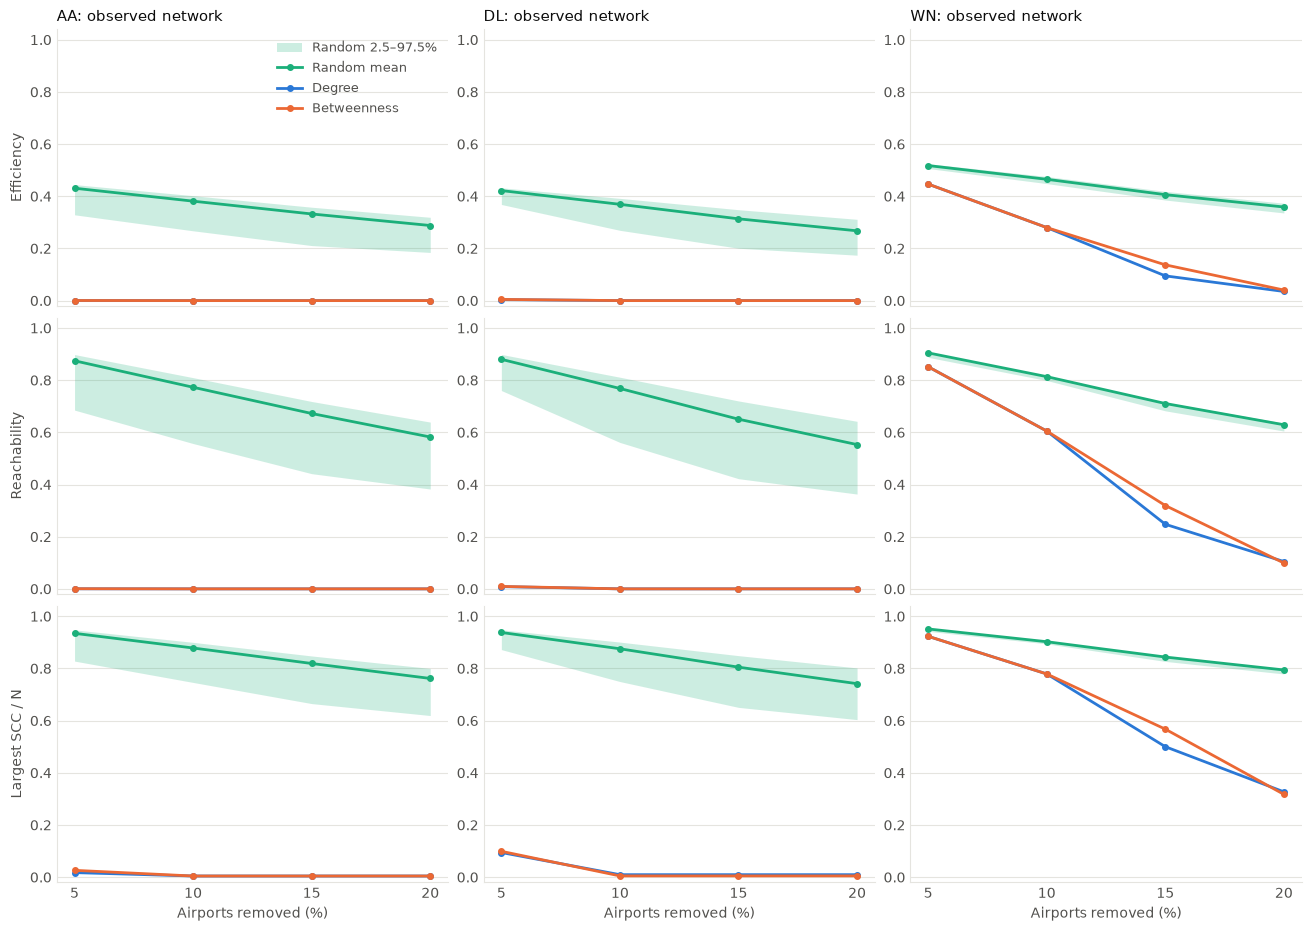

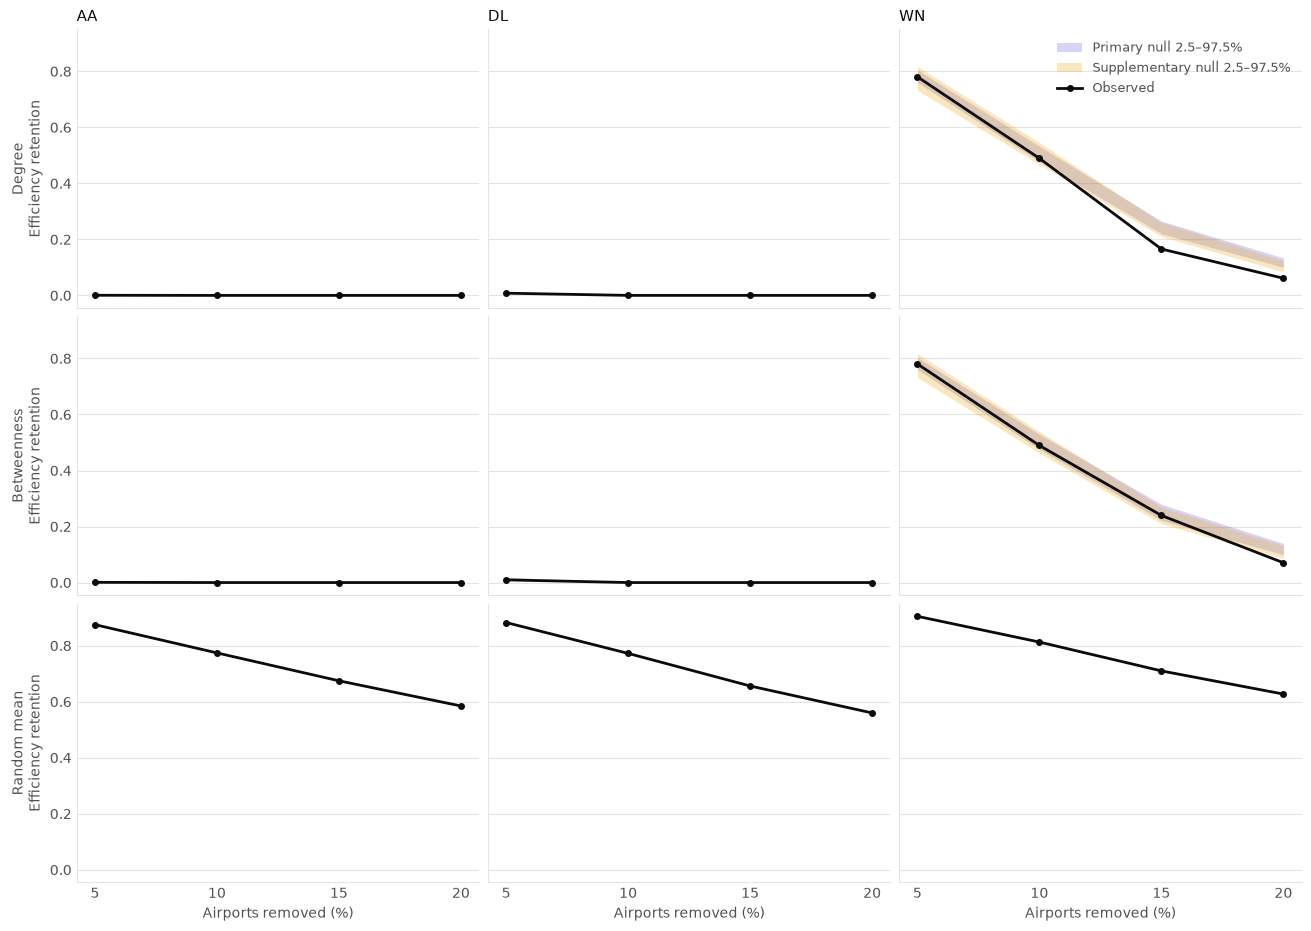

In [7]:
INK = "#0b0b0b"
MUTED = "#52514e"
GRID = "#e5e4df"
COLORS = {"Degree": "#2a78d6", "Betweenness": "#eb6834", "Random": "#1baf7a", "directed": "#6250d6", "reciprocal": "#eda100"}


def style_axis(ax):
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)
    ax.tick_params(colors=MUTED, length=0)
    ax.yaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)


fig, axes = plt.subplots(3, 3, figsize=(13, 9.2), constrained_layout=True, sharex=True)
labels = {"Efficiency": "Efficiency", "Reachability": "Reachability", "Largest SCC": "Largest SCC / N"}

for column, airline in enumerate(AIRLINES):
    intact = OBSERVED_RANDOM[airline]["intact"]
    values = OBSERVED_RANDOM[airline]["values"]
    for row, metric in enumerate(METRICS):
        ax = axes[row, column]
        m = METRICS.index(metric)
        low, high = np.percentile(values[:, :, m], [2.5, 97.5], axis=0)
        ax.fill_between(LEVELS, low, high, color=COLORS["Random"], alpha=0.22, linewidth=0, label="Random 2.5–97.5%")
        ax.plot(LEVELS, values[:, :, m].mean(axis=0), color=COLORS["Random"], marker="o", markersize=4, linewidth=2, label="Random mean")
        for strategy in STRATEGIES:
            frame = observed_lookup[(observed_lookup["Airline"] == airline) & (observed_lookup["Strategy"] == strategy)].sort_values("Level")
            ax.plot(frame["Level"], frame[metric], color=COLORS[strategy], marker="o", markersize=4, linewidth=2, label=strategy)
        ax.set_ylim(-0.02, max(intact[m], 1.0) + 0.04)
        ax.set_xticks(LEVELS)
        if row == 0:
            ax.set_title(f"{airline}: observed network", color=INK, fontsize=11, loc="left")
        if column == 0:
            ax.set_ylabel(labels[metric], color=MUTED)
        if row == 2:
            ax.set_xlabel("Airports removed (%)", color=MUTED)
        style_axis(ax)

axes[0, 0].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "06_h1_observed_resilience_curves.png", dpi=300, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(3, 3, figsize=(13, 9.2), constrained_layout=True, sharex=True, sharey=True)
strategy_names = STRATEGIES + [RANDOM_LABEL]
short = {"Degree": "Degree", "Betweenness": "Betweenness", RANDOM_LABEL: "Random mean"}

for column, airline in enumerate(AIRLINES):
    for row, strategy in enumerate(strategy_names):
        ax = axes[row, column]
        for model, table in (("directed", primary_cells_df), ("reciprocal", supplementary_cells_df)):
            frame = table[(table["Airline"] == airline) & (table["Strategy"] == strategy) & (table["Measure"] == "Efficiency retention")].sort_values("Level")
            ax.fill_between(frame["Level"], frame["Null 2.5%"], frame["Null 97.5%"], color=COLORS[model], alpha=0.25, linewidth=0, label=f"{'Primary' if model == 'directed' else 'Supplementary'} null 2.5–97.5%")
        frame = primary_cells_df[(primary_cells_df["Airline"] == airline) & (primary_cells_df["Strategy"] == strategy) & (primary_cells_df["Measure"] == "Efficiency retention")].sort_values("Level")
        ax.plot(frame["Level"], frame["Observed"], color=INK, marker="o", markersize=4, linewidth=2, label="Observed")
        ax.set_xticks(LEVELS)
        if row == 0:
            ax.set_title(f"{airline}", color=INK, fontsize=11, loc="left")
        if column == 0:
            ax.set_ylabel(f"{short[strategy]}\nEfficiency retention", color=MUTED)
        if row == 2:
            ax.set_xlabel("Airports removed (%)", color=MUTED)
        style_axis(ax)

axes[0, 2].legend(frameon=False, labelcolor=MUTED, fontsize=9)
fig.savefig(FIGURES / "06_h2_observed_vs_null_retention.png", dpi=300, bbox_inches="tight")
plt.show()

In [8]:
observed_step4 = pd.read_csv(TABLES / "04_null_structural_summary.csv")
for airline in AIRLINES:
    row = intact_df[(intact_df["Airline"] == airline) & (intact_df["Network set"] == "observed")].iloc[0]
    expected = observed_step4[(observed_step4["Airline"] == airline) & (observed_step4["Model"] == "directed")].set_index("Measure")["Observed"]
    check(f"{airline}: observed intact metrics match Step 4", all(np.isclose(row[column], expected[column], atol=1e-9) for column in ["Intact efficiency", "Intact reachability", "Intact largest SCC"]))

saved_baselines = pd.read_csv(TABLES / "04_null_structural_measures_and_intact_baselines.csv")
expansion_baselines = pd.read_csv(TABLES / "04_production_expansion_intact_baselines.csv")
combined_baselines = pd.concat([saved_baselines, expansion_baselines], ignore_index=True)
joined = intact_df[intact_df["Network set"] != "observed"].merge(combined_baselines, left_on=["Airline", "Network set", "Network"], right_on=["Airline", "Model", "Network"], suffixes=("", " Step 4"), validate="one_to_one")
check("Null intact baselines match Step 4 records", len(joined) == EXPECTED_PRIMARY * 3 + EXPECTED_SUPPLEMENTARY * 3 and all(
    np.isclose(joined[c], joined[f"{c} Step 4"], atol=1e-9).all() for c in ["Intact efficiency", "Intact reachability", "Intact largest SCC"]
), len(joined))

step4_outcomes = pd.concat([
    pd.read_csv(TABLES / "04_expansion_null_only_outcomes.csv"),
    pd.read_csv(TABLES / "04_expansion_null_only_outcomes_chains_100_199.csv")
], ignore_index=True).rename(columns={"Absolute efficiency": "Efficiency Step 4", "Efficiency retention": "Retention Step 4", "Reachability": "Reachability Step 4", "Largest SCC": "SCC Step 4"})
primary = outcomes_df[outcomes_df["Network set"] == "directed"]
merged = primary.merge(step4_outcomes, on=["Airline", "Network", "Strategy", "Level"], how="outer", validate="one_to_one", indicator=True)
check("Primary-null outcomes match Step 4 records for all networks", (merged["_merge"] == "both").all() and all(
    np.isclose(merged[a], merged[b], atol=1e-9).all() for a, b in [("Efficiency", "Efficiency Step 4"), ("Efficiency retention", "Retention Step 4"), ("Reachability", "Reachability Step 4"), ("Largest SCC", "SCC Step 4")]
), len(merged))

assessed = pd.read_csv(TABLES / "04_expansion_200_cell_assessment.csv")
cells = primary_cells_df.copy()
cells["Precision measure"] = cells["Measure"].map(MEASURE_TO_PRECISION)
joined_limits = cells.merge(assessed, left_on=["Airline", "Strategy", "Level", "Precision measure"], right_on=["Airline", "Strategy", "Level", "Measure"], suffixes=("", " assessed"), validate="one_to_one")
check("Primary-null intervals match the 200-network Step 4 assessment", len(joined_limits) == 144 and np.isclose(joined_limits["Null 2.5%"], joined_limits["Null 2.5% (200)"], atol=1e-9).all() and np.isclose(joined_limits["Null 97.5%"], joined_limits["Null 97.5% (200)"], atol=1e-9).all(), len(joined_limits))

for airline in AIRLINES:
    n = OBS[airline]["n"]
    bad = 0
    for model in NETWORK_SETS:
        store = TRIAL_STORE[(airline, model)]
        bad += int((np.diff(store, axis=2) > 1e-12).sum())
    check(f"{airline}: random-removal metrics never increase across nested levels", bad == 0, bad)

    frame = outcomes_df[outcomes_df["Airline"] == airline].copy()
    frame["K"] = frame["Level"].map(LEVEL_K[airline])
    check(f"{airline}: reachability and largest SCC respect removal ceilings", (
        (frame["Reachability"] <= (n - frame["K"]) * (n - frame["K"] - 1) / (n * (n - 1)) + 1e-12).all()
        and (frame["Largest SCC"] <= (n - frame["K"]) / n + 1e-12).all()
        and (frame["Efficiency"] <= frame["Reachability"] + 1e-12).all()
    ))

for airline in AIRLINES:
    obs = OBS[airline]
    n = obs["n"]
    for model in NETWORK_SETS:
        network, source, target = load_networks(airline, model)[0]
        ranking = load_rankings(airline, model)[network]
        A = directed_matrix(source, target, n)
        for removed in [ranking["Betweenness"][:LEVEL_K[airline][20]], RANDOM_ORDERS[airline][0][:LEVEL_K[airline][20]]]:
            value = after_removal(A, removed, n)
            keep = set(np.setdiff1d(np.arange(n), removed).tolist())
            G = nx.DiGraph()
            G.add_nodes_from(keep)
            G.add_edges_from((s, t) for s, t in zip(source.tolist(), target.tolist()) if s in keep and t in keep)
            lengths = [d for u, targets in nx.all_pairs_shortest_path_length(G) for v, d in targets.items() if u != v]
            denominator = n * (n - 1)
            check(f"{airline} {model}: SciPy matches NetworkX after removal", (
                np.isclose(value[0], sum(1 / d for d in lengths) / denominator, atol=1e-12)
                and np.isclose(value[1], len(lengths) / denominator, atol=1e-12)
                and np.isclose(value[2], max(map(len, nx.strongly_connected_components(G))) / n, atol=1e-12)
            ))

check("Expected network counts", intact_df.groupby("Network set").size().to_dict() == {"directed": EXPECTED_PRIMARY * 3, "observed": 3, "reciprocal": EXPECTED_SUPPLEMENTARY * 3}, intact_df.groupby("Network set").size().to_dict())
check("Row counts", len(outcomes_df) == intact_df.shape[0] * 12, len(outcomes_df))

precision_summary = primary_cells_df.assign(
    E1=lambda d: d["E1 flagged at 200 networks"], E2=lambda d: d["E2 flagged at 200 networks"]
).groupby(["Airline", "Strategy", "Level", "Measure"])[["E1", "E2", "Zero-width interval", "Near-zero interval (width at or below 0.001)"]].first().reset_index()
precision_summary.to_csv(TABLES / "06_h2_precision_flags.csv", index=False)
validation_df = pd.DataFrame(validation)
validation_df.to_csv(TABLES / "06_validation_checks.csv", index=False)
pd.DataFrame([{"Stage": k, "Seconds": v} for k, v in timings.items()]).to_csv(TABLES / "06_runtime.csv", index=False)
print(validation_df["Result"].value_counts().to_string())
print("Step 7 and single-airport removal were not run.")

Result
PASS    35
Step 7 and single-airport removal were not run.


> Historical stage note: this describes the state when this section was first executed. Steps 1–7 are now complete; see the final report and validation record for current status.

### Step 6 status

**H1 (observed networks; ID-tie rankings are official):** Supported for AA, DL and WN under both degree-targeted and betweenness-targeted removal. No tie order changed any H1 verdict.

**H2 (primary directed null only):** Not supported for AA, DL or WN under the approved rule. This does not show that degrees fully explain resilience. The AA and DL targeted results reach a floor near zero at low removal levels, where many null intervals are zero-width or near zero, so differences there cannot be detected.

**Supplementary reciprocal-pair null:** reported separately in `06_supplementary_null_cells.csv` and does not affect the H2 verdicts.

In the deviation tables, the text "None" means no systematic deviation. Reading those CSV files with pandas requires `keep_default_na=False` to retain that text.

Step 7 and single-airport removals have not started.